# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\ololl\Desktop\remote\study\MMDA\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy.special import expit
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.utils import ClassifierTags
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42
pd.set_option('display.precision', 4)


## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) - начальные веса (w0[0] - свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def __sklearn_tags__(self):
        # Совместимость с sklearn >= 1.6 при заданном порядке базовых классов.
        tags = BaseEstimator.__sklearn_tags__(self)
        tags.estimator_type = 'classifier'
        tags.classifier_tags = ClassifierTags()
        tags.target_tags.required = True
        return tags

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) == 0:
            raise ValueError('Ожидаются непустые X размера (N, d) и y размера (N,)')
        if not np.isfinite(X).all() or not np.isin(y, [0, 1]).all():
            raise ValueError('Нужны конечные признаки и метки 0/1')
        if self.gd_type not in ('full', 'stochastic'):
            raise ValueError('gd_type: full или stochastic')
        if self.max_iter < 1 or self.eta <= 0 or self.tolerance < 0 or self.batch_size < 1:
            raise ValueError('Некорректные параметры спуска')
        self.classes_ = np.array([0, 1])
        self.n_features_in_ = X.shape[1]
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)
        X = np.column_stack((np.ones(len(X)), X))
        self.w = (np.zeros(X.shape[1]) if self.w0 is None
                  else np.array(self.w0, dtype=float, copy=True))
        if self.w.shape != (X.shape[1],) or not np.isfinite(self.w).all():
            raise ValueError('w0 должен иметь размер d + 1 и конечные значения')
        self.stop_reason_ = 'max_iter'
        for iteration in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X, y))
            if self.gd_type == 'full':
                gradient = self.calc_gradient(X, y)
            else:
                # Как в calc_grad_on_batch с семинара: выборка с повторениями.
                sample = rng.integers(len(y), size=self.batch_size)
                gradient = self.calc_gradient(X[sample], y[sample])
            step = self.eta * gradient
            self.w -= step
            self.n_iter_ = iteration + 1
            if np.linalg.norm(step) < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break
        self.final_loss_ = self.calc_loss(X, y)
        return self

    def sigmoid(self, z):
        return expit(np.asarray(z, dtype=float))

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise RuntimeError('Not trained yet')
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_ or not np.isfinite(X).all():
            raise ValueError('Неверный размер или неконечные значения X')
        X = np.column_stack((np.ones(len(X)), X))
        p = self.sigmoid(X @ self.w)
        return np.column_stack((1 - p, p))

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise RuntimeError('Not trained yet')
        if not 0 <= threshold <= 1:
            raise ValueError('threshold должен лежать в [0, 1]')
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) - уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) - градиент log-loss по self.w
        """
        return X.T @ (self.sigmoid(X @ self.w) - y) / len(y)

    def calc_loss(self, X, y):
        # logaddexp вычисляет log(1 + exp(z)) без log(0) и переполнения.
        """
        X: np.array размера (N, d + 1) - уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float - значение log-loss при текущих self.w
        """
        z = X @ self.w
        return float(np.mean(np.logaddexp(0, z) - y * z))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным - проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 3.27e-11


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

,iterations,stop,final_loss
method,,,
GD,1000,max_iter,0.5124
SGD,1000,max_iter,0.5121


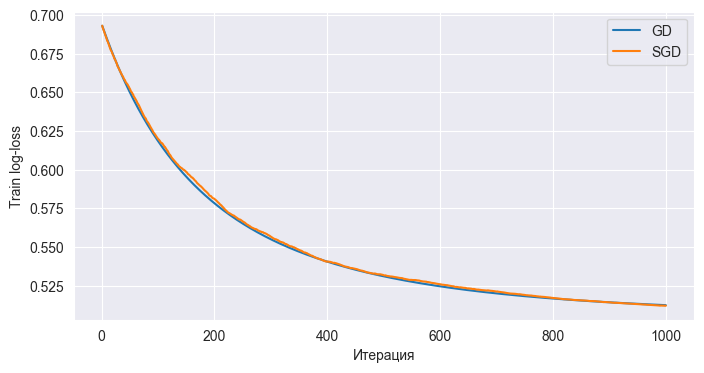

In [6]:
gd = LogReg(gd_type='full').fit(X_train, y_train)
sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)
convergence = pd.DataFrame([
    {'method': name, 'iterations': model.n_iter_, 'stop': model.stop_reason_,
     'final_loss': model.final_loss_}
    for name, model in [('GD', gd), ('SGD', sgd)]
]).set_index('method')
display(convergence)
fig, ax = plt.subplots(figsize=(8, 4))
for name, model in [('GD', gd), ('SGD', sgd)]:
    ax.plot(np.arange(1, len(model.loss_history) + 1), model.loss_history, label=name)
ax.set(xlabel='Итерация', ylabel='Train log-loss')
ax.legend()
plt.show()


GD и SGD остановились по max_iter: по 1000 шагов. Шум случайных батчей мешает SGD достичь tolerance при постоянном шаге. Кривая GD гладкая, у SGD есть колебания.

Градиент GD использует 14 000 объектов, SGD - 32 выборки с повторениями. Для loss_history оба метода дополнительно вычисляют потери на всех 14 000 объектах.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

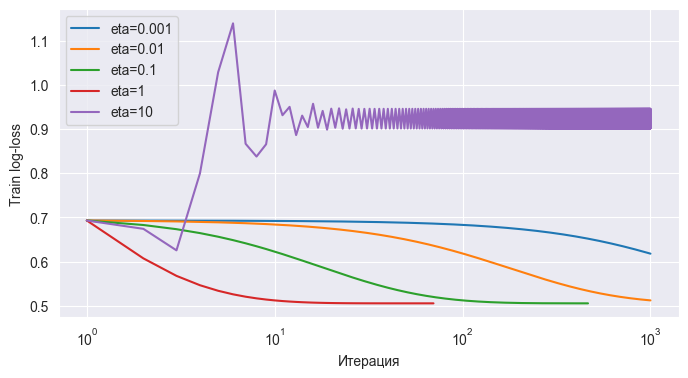

,final_loss,iterations,stop
eta,,,
0.001,0.6181,1000,max_iter
0.010,0.5124,1000,max_iter
0.100,0.5058,465,tolerance
1.000,0.5058,70,tolerance
10.000,0.9013,1000,max_iter


In [7]:
eta_models = {}
fig, ax = plt.subplots(figsize=(8, 4))
for eta in [1e-3, 1e-2, 1e-1, 1, 10]:
    model = LogReg(eta=eta).fit(X_train, y_train)
    eta_models[eta] = model
    ax.plot(np.arange(1, len(model.loss_history) + 1), model.loss_history, label=f'eta={eta:g}')
ax.set(xscale='log', xlabel='Итерация', ylabel='Train log-loss')
ax.legend()
plt.show()
eta_results = pd.DataFrame([
    {'eta': eta, 'final_loss': model.final_loss_, 'iterations': model.n_iter_,
     'stop': model.stop_reason_} for eta, model in eta_models.items()
]).set_index('eta')
display(eta_results)


При eta=0.001 за 1000 шагов loss остаётся 0.6181; при eta=0.1 и 1 спуск достигает примерно 0.5058 за 465 и 70 шагов. При eta=10 возникают колебания, итоговый loss=0.9013. Малый шаг замедляет сходимость, слишком большой перескакивает минимум. Малое изменение весов при очень маленьком eta ещё не доказывает достижение минимума.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sklearn_synthetic = LogisticRegression(random_state=RANDOM_STATE).fit(X_train, y_train)
synthetic_metrics = pd.DataFrame([
    {'model': name, 'accuracy': metrics.accuracy_score(y_test, model.predict(X_test)),
     'ROC-AUC': metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])}
    for name, model in [('GD', gd), ('SGD', sgd), ('sklearn', sklearn_synthetic)]
]).set_index('model')
display(synthetic_metrics)
weights = pd.DataFrame({'GD': gd.w, 'sklearn': np.r_[
    sklearn_synthetic.intercept_, sklearn_synthetic.coef_.ravel()]},
    index=['intercept'] + [f'x{i}' for i in range(X_train.shape[1])])
weights['difference'] = weights['GD'] - weights['sklearn']
display(weights)
# Та же нерегуляризованная задача, с более строгой точностью решения.
gd_precise = LogReg(eta=1, tolerance=1e-8, max_iter=20000).fit(X_train, y_train)
sklearn_unpenalized = LogisticRegression(
    penalty=None, max_iter=20000, tol=1e-10, random_state=RANDOM_STATE
).fit(X_train, y_train)
unpenalized_weights = np.r_[sklearn_unpenalized.intercept_, sklearn_unpenalized.coef_.ravel()]
print('Максимальное расхождение весов без регуляризации:',
      np.max(np.abs(gd_precise.w - unpenalized_weights)))


,accuracy,ROC-AUC
model,,
GD,0.7820,0.8388
SGD,0.7825,0.8388
sklearn,0.7765,0.8387


,GD,sklearn,difference
intercept,-0.0021,-0.0219,0.0198
x0,0.0061,0.0027,0.0033
x1,0.0070,0.0090,-0.0021
x2,-0.5472,-0.7227,0.1755
x3,-0.1445,-0.2623,0.1178
x4,0.0125,0.0166,-0.0041
x5,-0.0063,-0.0115,0.0052
x6,0.0008,0.0056,-0.0048
x7,0.0391,0.0572,-0.0181
x8,-0.0024,-0.0012,-0.0012


Максимальное расхождение весов без регуляризации: 5.4141542249475094e-08


Метрики близки, но не совпадают точно; веса также различаются. В sklearn по умолчанию есть L2-регуляризация (C=1), другой оптимизатор и критерий остановки. Наш GD за 1000 шагов не достиг tolerance. Для той же задачи без штрафа задаём penalty=None; при более строгой точности решения веса здесь совпадают с погрешностью около 5e-8.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
print('Пропуски:', df.isna().sum().sum())
print('Полные дубликаты:', df.duplicated().sum())
print('Prevalence train:', y_train.mean(), 'test:', y_test.mean())
baseline = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
baseline.fit(X_train, y_train)
p_baseline = baseline.predict_proba(X_test)[:, 1]
pred_baseline = (p_baseline >= 0.5).astype(int)
display(pd.Series({
    'Всегда 0': metrics.accuracy_score(y_test, np.zeros(len(y_test))),
    'LogisticRegression': metrics.accuracy_score(y_test, pred_baseline)
}, name='accuracy').to_frame())


Пропуски: 0
Полные дубликаты: 1177
Prevalence train: 0.19661315152848033 test: 0.19641025641025642


,accuracy
Всегда 0,0.8036
LogisticRegression,0.8200


Пропусков нет, полных повторов 1177. Без ID нельзя уверенно отличить повторную запись от независимых образцов с одинаковыми измерениями. Сохраняю данные и split из задания. Совпадения между train и test могут завышать оценку качества на новых профилях.

Stratify сохраняет доли классов. Ответ "всегда 0" даёт высокую accuracy, хотя не находит хороших вин; нужны precision и recall.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP=98, TN=1501, FP=66, FN=285


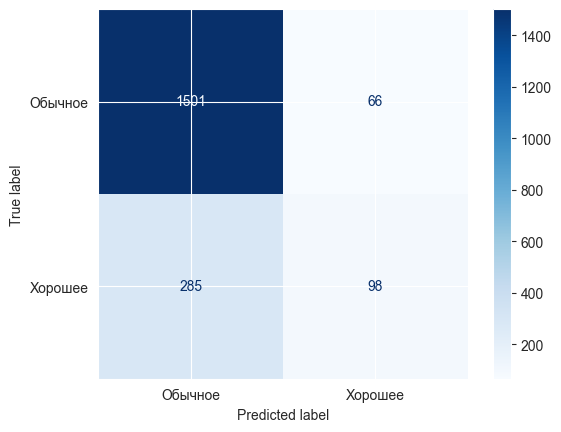

In [12]:
truth = y_test.to_numpy()
TP = int(np.sum((truth == 1) & (pred_baseline == 1)))
TN = int(np.sum((truth == 0) & (pred_baseline == 0)))
FP = int(np.sum((truth == 0) & (pred_baseline == 1)))
FN = int(np.sum((truth == 1) & (pred_baseline == 0)))
manual_cm = np.array([[TN, FP], [FN, TP]])
assert np.array_equal(manual_cm, metrics.confusion_matrix(y_test, pred_baseline))
print(f'TP={TP}, TN={TN}, FP={FP}, FN={FN}')
metrics.ConfusionMatrixDisplay(manual_cm, display_labels=['Обычное', 'Хорошее']).plot(cmap='Blues')
plt.show()


FP=66 - рекомендовали посредственное вино; FN=285 - пропустили хорошее. Чаще встречаются FN: при пороге 0.5 модель редко выбирает положительный класс.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision = TP / (TP + FP) if TP + FP else 0.0
recall = TP / (TP + FN) if TP + FN else 0.0
def manual_fbeta(beta):
    denominator = beta**2 * precision + recall
    return (1 + beta**2) * precision * recall / denominator if denominator else 0.0
manual_scores = np.array([precision, recall, manual_fbeta(1), manual_fbeta(0.5), manual_fbeta(2)])
sklearn_scores = np.array([
    metrics.precision_score(y_test, pred_baseline, zero_division=0),
    metrics.recall_score(y_test, pred_baseline, zero_division=0),
    *[metrics.fbeta_score(y_test, pred_baseline, beta=b, zero_division=0) for b in [1, 0.5, 2]]
])
np.testing.assert_allclose(manual_scores, sklearn_scores)
display(pd.DataFrame({'Вручную': manual_scores, 'sklearn': sklearn_scores},
                     index=['precision', 'recall', 'F1', 'F0.5', 'F2']))


,Вручную,sklearn
precision,0.5976,0.5976
recall,0.2559,0.2559
F1,0.3583,0.3583
F0.5,0.4716,0.4716
F2,0.2889,0.2889


F0.5 сильнее учитывает precision, F2 - recall. Если посредственные вина особенно разочаровывают клиентов, выбираю F0.5; для широкой подборки - F2. F1 одинаково учитывает обе метрики.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

,eta,validation_loss,iterations,stop
0,0.1,0.3939,15000,max_iter
1,0.5,0.3938,6324,tolerance
2,1.0,0.3938,3470,tolerance


Итоговый спуск: 3765 tolerance


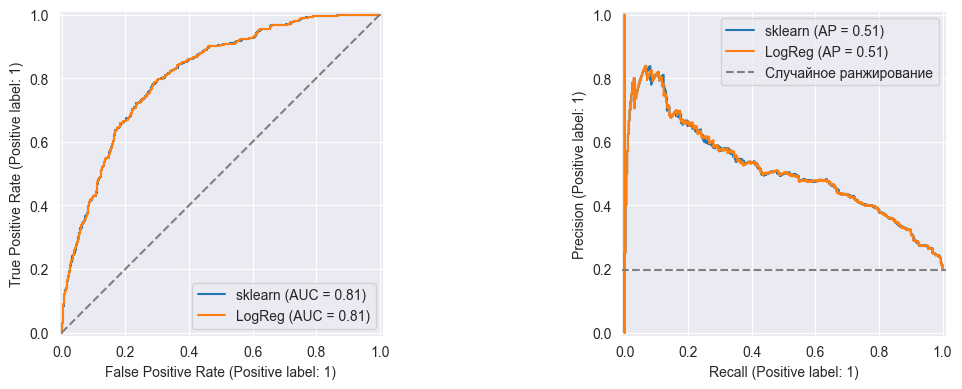

,ROC-AUC,PR-AUC (AP)
model,,
sklearn,0.8135,0.5121
LogReg,0.8135,0.5122


,ROC-AUC
p,0.8135
10p,0.8135
p^3,0.8135
logit(p),0.8135
-p,0.1865
Метки 0/1,0.6069


Уровень PR случайной модели: 0.19641025641025642


In [14]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)
# Параметры собственного спуска выбираем только по train-части и валидации.
custom_candidates = []
for eta in [0.1, 0.5, 1.0]:
    candidate = make_pipeline(StandardScaler(), LogReg(
        eta=eta, max_iter=15000, tolerance=1e-6, random_state=RANDOM_STATE))
    candidate.fit(X_fit, y_fit)
    custom_candidates.append({
        'eta': eta, 'validation_loss': metrics.log_loss(y_val, candidate.predict_proba(X_val)),
        'iterations': candidate[-1].n_iter_, 'stop': candidate[-1].stop_reason_
    })
custom_search = pd.DataFrame(custom_candidates)
display(custom_search)
converged = custom_search.loc[custom_search['stop'].eq('tolerance')]
assert not converged.empty, 'Увеличьте max_iter на тренировочных данных'
best_eta = float(converged.sort_values('validation_loss').iloc[0]['eta'])
custom_wine = make_pipeline(StandardScaler(), LogReg(
    eta=best_eta, max_iter=20000, tolerance=1e-6, random_state=RANDOM_STATE))
custom_wine.fit(X_train, y_train)
print('Итоговый спуск:', custom_wine[-1].n_iter_, custom_wine[-1].stop_reason_)
assert custom_wine[-1].stop_reason_ == 'tolerance'
p_custom = custom_wine.predict_proba(X_test)[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, p in [('sklearn', p_baseline), ('LogReg', p_custom)]:
    metrics.RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[0])
    metrics.PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[1].axhline(y_test.mean(), ls='--', color='gray', label='Случайное ранжирование')
axes[1].legend()
plt.tight_layout()
plt.show()
auc_comparison = pd.DataFrame([
    {'model': name, 'ROC-AUC': metrics.roc_auc_score(y_test, p),
     'PR-AUC (AP)': metrics.average_precision_score(y_test, p)}
    for name, p in [('sklearn', p_baseline), ('LogReg', p_custom)]
]).set_index('model')
display(auc_comparison)
p = np.clip(p_baseline, np.finfo(float).eps, 1 - np.finfo(float).eps)
display(pd.Series({name: metrics.roc_auc_score(y_test, scores) for name, scores in {
    'p': p, '10p': 10 * p, 'p^3': p**3, 'logit(p)': np.log(p / (1 - p)),
    '-p': -p, 'Метки 0/1': pred_baseline
}.items()}, name='ROC-AUC').to_frame())
print('Уровень PR случайной модели:', y_test.mean())


ROC-AUC немного выше у sklearn (0.813537 против 0.813512), AP - у LogReg (0.512230 против 0.512115). Ранжирование различается, но разница мала.

10p, p^3 и logit(p) сохраняют порядок и ROC-AUC; для -p получается 1 - AUC. По меткам 0/1 остаётся одна рабочая точка: AUC=(TPR+TNR)/2, информация о ранжировании теряется.

Базовый уровень PR равен доле хороших вин, 0.1964: это ожидаемая precision случайной подборки. PR-AUC здесь считается через average precision.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

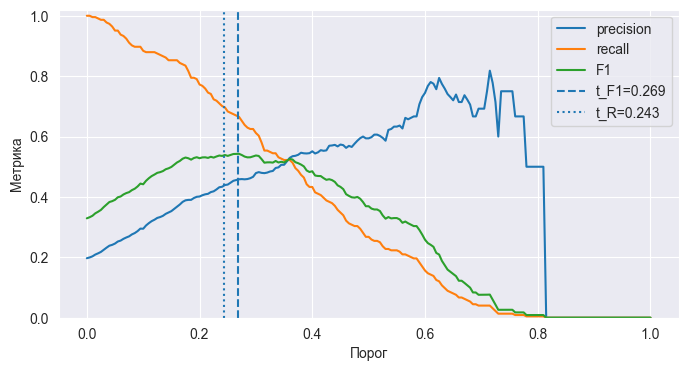

Выбор по валидации:


,threshold,precision,recall,F1
t_F1,0.2689,0.4601,0.6696,0.5455
t_R,0.2432,0.4385,0.7009,0.5395


,threshold,precision,recall,F1
0.5,0.5000,0.5976,0.2559,0.3583
t_F1,0.2689,0.4739,0.6397,0.5444
t_R,0.2432,0.4370,0.6789,0.5317


На тесте recall >= 0.7: False


In [15]:
validation_model = clone(baseline).fit(X_fit, y_fit)
p_val = validation_model.predict_proba(X_val)[:, 1]
def threshold_row(y_true, p, threshold):
    pred = (p >= threshold).astype(int)
    return {'threshold': float(threshold),
            'precision': metrics.precision_score(y_true, pred, zero_division=0),
            'recall': metrics.recall_score(y_true, pred, zero_division=0),
            'F1': metrics.f1_score(y_true, pred, zero_division=0)}
# Все различные разбиения валидационных вероятностей, включая крайние пороги.
thresholds = np.unique(np.r_[0.0, p_val, 1.0])
validation_thresholds = pd.DataFrame([threshold_row(y_val, p_val, t) for t in thresholds])
t_F1 = float(validation_thresholds.sort_values(
    ['F1', 'precision', 'threshold'], ascending=False).iloc[0]['threshold'])
t_R = float(validation_thresholds.loc[validation_thresholds['recall'] >= 0.7].sort_values(
    ['precision', 'recall', 'threshold'], ascending=False).iloc[0]['threshold'])
fig, ax = plt.subplots(figsize=(8, 4))
plot_grid = pd.DataFrame([threshold_row(y_val, p_val, t) for t in np.linspace(0, 1, 201)])
for metric in ['precision', 'recall', 'F1']:
    ax.plot(plot_grid['threshold'], plot_grid[metric], label=metric)
ax.axvline(t_F1, ls='--', label=f't_F1={t_F1:.3f}')
ax.axvline(t_R, ls=':', label=f't_R={t_R:.3f}')
ax.set(xlabel='Порог', ylabel='Метрика', ylim=(0, 1.02))
ax.legend()
plt.show()
print('Выбор по валидации:')
display(pd.DataFrame([threshold_row(y_val, p_val, t_F1), threshold_row(y_val, p_val, t_R)],
                     index=['t_F1', 't_R']))
# Финальный порог для сервиса заранее выбираем по ограничению recall на валидации.
selected_threshold = t_R
final_unweighted = clone(baseline).fit(X_train, y_train)
p_final = final_unweighted.predict_proba(X_test)[:, 1]
threshold_test = pd.DataFrame([
    threshold_row(y_test, p_final, t) for t in [0.5, t_F1, t_R]
], index=['0.5', 't_F1', 't_R'])
display(threshold_test)
print('На тесте recall >= 0.7:', bool(threshold_test.loc['t_R', 'recall'] >= 0.7))


t_F1=0.2689, t_R=0.2432. При t_R на тесте precision=0.4370, recall=0.6789, F1=0.5317. Условие recall >= 0.7 не выполнено. Для сценария выбираю t_R по валидационному ограничению. Разница выборок и переобучение на всём train не гарантируют тот же recall на новых данных. Перед внедрением нужна дополнительная валидация с запасом по recall; по тесту порог не меняю.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
def evaluate_model(name, model, threshold=0.5):
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= threshold).astype(int)
    return {'model': name, 'threshold': threshold,
            'accuracy': metrics.accuracy_score(y_test, pred),
            'precision': metrics.precision_score(y_test, pred, zero_division=0),
            'recall': metrics.recall_score(y_test, pred, zero_division=0),
            'F1': metrics.f1_score(y_test, pred, zero_division=0),
            'ROC-AUC': metrics.roc_auc_score(y_test, p),
            'PR-AUC': metrics.average_precision_score(y_test, p)}
balanced = make_pipeline(StandardScaler(), LogisticRegression(
    class_weight='balanced', random_state=RANDOM_STATE)).fit(X_train, y_train)
class_counts = y_train.value_counts().sort_index()
class_weights = len(y_train) / (2 * class_counts)
display(pd.DataFrame({'n': class_counts, 'weight': class_weights}))
imbalance_rows = [evaluate_model('LR', baseline), evaluate_model('LR balanced', balanced)]
display(pd.DataFrame(imbalance_rows).set_index('model'))


,n,weight
target,,
0,3653,0.6224
1,894,2.5431


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
LR,0.5,0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
LR balanced,0.5,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005


Веса n/(2*n_k): класс 0 - 0.6224, класс 1 - 2.5431. Recall растёт с 0.2559 до 0.7546, precision падает с 0.5976 до 0.3970, accuracy - с 0.8200 до 0.7267. ROC-AUC и AP меняются слабее: веса сильнее меняют решения при пороге 0.5, чем ранжирование.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
    'NearMiss': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE)
}
resampling_models = {}
resampled_counts = []
for name, sampler in samplers.items():
    model = make_imb_pipeline(StandardScaler(), clone(sampler),
                              LogisticRegression(random_state=RANDOM_STATE))
    model.fit(X_train, y_train)
    resampling_models[name] = model
    # Повторяем только train-ресемплинг для явного подсчёта размеров классов.
    _, y_resampled = clone(sampler).fit_resample(model[0].transform(X_train), y_train)
    counts = pd.Series(y_resampled).value_counts()
    resampled_counts.append({'method': name, 'class_0': counts[0], 'class_1': counts[1]})
    imbalance_rows.append(evaluate_model(name, model))
display(pd.DataFrame(resampled_counts).set_index('method'))
imbalance_table = pd.DataFrame(imbalance_rows).set_index('model')
display(imbalance_table)
reversed_smote = make_imb_pipeline(
    SMOTE(random_state=RANDOM_STATE), StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)).fit(X_train, y_train)
order_comparison = pd.DataFrame([
    evaluate_model('Scaler -> SMOTE', resampling_models['SMOTE']),
    evaluate_model('SMOTE -> Scaler', reversed_smote)
]).set_index('model')
display(order_comparison)


,class_0,class_1
method,,
RandomUnderSampler,894,894
NearMiss,894,894
RandomOverSampler,3653,3653
SMOTE,3653,3653


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
LR,0.5,0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
LR balanced,0.5,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
RandomUnderSampler,0.5,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
NearMiss,0.5,0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
RandomOverSampler,0.5,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
SMOTE,0.5,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
Scaler -> SMOTE,0.5,0.7292,0.3992,0.7493,0.5209,0.8125,0.504
SMOTE -> Scaler,0.5,0.7338,0.4042,0.7493,0.5252,0.8116,0.509


Imblearn Pipeline поддерживает fit_resample. Ресемплинг работает только при fit; при predict тест масштабируется без балансировки. Балансировка до split создаёт утечку через повторы, синтетические точки или тестовых соседей и искажает доли классов.

Среди четырёх методов лучший AP у SMOTE (0.5040), худший у NearMiss (0.4001). SMOTE расширяет представление редкого класса; NearMiss удаляет большую часть класса 0 и меняет его распределение. Это возможное объяснение.

Для NearMiss и SMOTE масштабирование меняет расстояния и соседей, поэтому порядок шагов важен. У случайных методов выбор объектов от масштаба не зависит, но scaler после ресемплинга оценивает другие средние и дисперсии, что тоже может влиять на регуляризованную модель. Смена порядка проверена для SMOTE в таблице. Обычный SMOTE может создавать дробный is_red.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
"LR balanced, t=0.5",0.5000,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
"LR, t_F1",0.2689,0.7897,0.4739,0.6397,0.5444,0.8135,0.5121


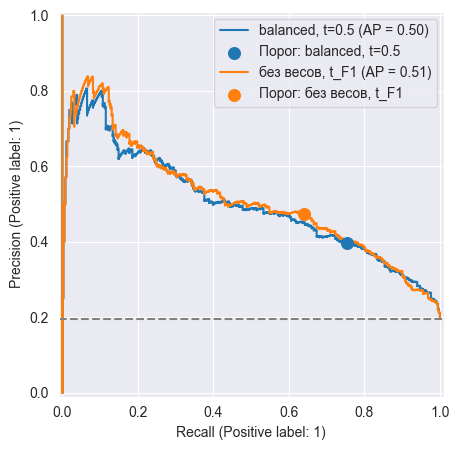

In [18]:
weights_vs_threshold = pd.DataFrame([
    evaluate_model('LR balanced, t=0.5', balanced),
    evaluate_model('LR, t_F1', final_unweighted, t_F1)
]).set_index('model')
display(weights_vs_threshold)
fig, ax = plt.subplots(figsize=(7, 5))
for name, model, threshold in [
    ('balanced, t=0.5', balanced, 0.5), ('без весов, t_F1', final_unweighted, t_F1)
]:
    p = model.predict_proba(X_test)[:, 1]
    metrics.PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=ax)
    point = threshold_row(y_test, p, threshold)
    ax.scatter(point['recall'], point['precision'], s=70, label=f'Порог: {name}', zorder=5)
ax.axhline(y_test.mean(), ls='--', color='gray')
ax.legend()
plt.show()


PR-кривые близки: веса в основном меняют рабочую точку в сторону большего recall. Это не строго эквивалентно смене порога: при переобучении меняются коэффициенты, а значит, может измениться и ранжирование. При идеальной спецификации и без регуляризации эффект весов сводится к сдвигу логарифма шансов.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
all_rows = list(imbalance_rows)
all_rows += [evaluate_model('LogReg GD', custom_wine),
             evaluate_model('LR, t_F1', final_unweighted, t_F1),
             evaluate_model('LR, t_R', final_unweighted, t_R),
             evaluate_model('SMOTE -> Scaler', reversed_smote)]
all_rows.append({'model': 'Всегда 0', 'threshold': 0.5,
                 'accuracy': metrics.accuracy_score(y_test, np.zeros(len(y_test))),
                 'precision': 0.0, 'recall': 0.0, 'F1': 0.0, 'ROC-AUC': 0.5,
                 'PR-AUC': float(y_test.mean())})
all_metrics = pd.DataFrame(all_rows).set_index('model')
display(all_metrics)
print('Выбор для сервиса: LR без весов, t_R =', selected_threshold)


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
LR,0.5000,0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
LR balanced,0.5000,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
RandomUnderSampler,0.5000,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
NearMiss,0.5000,0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
RandomOverSampler,0.5000,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
SMOTE,0.5000,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040
LogReg GD,0.5000,0.8215,0.6036,0.2663,0.3696,0.8135,0.5122
"LR, t_F1",0.2689,0.7897,0.4739,0.6397,0.5444,0.8135,0.5121
"LR, t_R",0.2432,0.7651,0.4370,0.6789,0.5317,0.8135,0.5121


Выбор для сервиса: LR без весов, t_R = 0.2431963641816194


Для демонстрации выбираю LR без весов с t_R=0.2432: precision=0.4370, recall=0.6789, F1=0.5317. При пороге 0.5 recall=0.2559. Порог выбран по валидации; тестовые сравнения не используются для повторного выбора. Перед внедрением нужна новая валидация: целевой recall >= 0.7 на этом тесте не достигнут.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)
final_model = final_unweighted
final_threshold = selected_threshold
joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps(
    {'threshold': float(final_threshold), 'features': list(X_train.columns)},
    ensure_ascii=False, indent=2), encoding='utf-8')
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)
X_test.head(5).to_csv(app_dir / 'example.csv', index=False)
all_metrics.to_csv(app_dir / 'metrics.csv', encoding='utf-8-sig')
loaded = joblib.load(app_dir / 'model.joblib')
np.testing.assert_allclose(loaded.predict_proba(X_test), final_model.predict_proba(X_test))
print('Сохранены пайплайн, порог и тестовая выборка:', app_dir)

Сохранены пайплайн, порог и тестовая выборка: wine_app


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

Приложение: https://mmda-hw3-wine-m3vmyphumuqfgeutryafeq.streamlit.app/

Репозиторий: https://github.com/Kurban4ik/mmda-hw3-wine .

Приложение и модель: wine_app/. Архив для сдачи: wine_app.zip.

Локальный запуск: python -m streamlit run wine_app/app.py. Python 3.13.